# 📰 Fake News Detector: Partial Code Implementation (Preprocessing & EDA)

**Author / Project:** FakeNewsDetector Machine Learning Pipeline  
**Dataset:** LIAR Benchmark Dataset (Wang, 2017) — 12,836 labeled real-world political claims  
**Scope:** Data Ingestion, Comprehensive Exploratory Data Analysis (EDA), Text Cleaning, and Preprocessing  

---

### 🎯 Objectives of this Implementation:
1. **Ingest & Inspect:** Load canonical LIAR benchmark splits (`train.tsv`, `valid.tsv`, `test.tsv`).
2. **Exploratory Data Analysis (EDA):**
   - Analyze original 6 PolitiFact veracity ratings and class distributions.
   - Map granular labels to actionable 3-tier target taxonomy (`TRUE`, `MISLEADING`, `FALSE`).
   - Examine speaker truthfulness ratios and identify high-frequency political figures.
   - Study text length, word count distributions, and lexical dispersion.
   - Analyze top subjects and categories featured in contested claims.
3. **Preprocessing Pipeline:**
   - Clean raw text (remove URLs, HTML tags, special symbols, multiple spaces).
   - Construct multi-column composite features (`statement` + `subjects` + `speaker` + `job` + `context`).
4. **Feature Extraction (TF-IDF):**
   - Extract unigrams and bigrams with sublinear TF scaling.
   - Inspect discriminative vocabulary per veracity category.
5. **Artifact Preparation:** Prepare structured arrays ready for classifier training (`ml_service/train.py`).

## 1. Setup & Environment Dependencies
Import essential libraries for numerical computing, data analysis, visualization, and natural language processing.

In [1]:
import os
import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

# Visualization settings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('deep')
%matplotlib inline

print("✅ Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


✅ Libraries imported successfully!


## 2. Dataset Ingestion
The LIAR dataset is structured without column headers in TSV format. The 14 canonical columns defined in the original benchmark paper are:
- `id`: Unique record identifier
- `label`: Original PolitiFact rating (`pants-fire`, `false`, `barely-true`, `half-true`, `mostly-true`, `true`)
- `statement`: The claim / quote under verification
- `subjects`: Subject matter categories (comma-delimited)
- `speaker`: The entity / politician who made the statement
- `job`: Job title of the speaker
- `state`: State affiliation
- `party`: Political party
- `barely_true_counts`, `false_counts`, `half_true_counts`, `mostly_true_counts`, `pants_on_fire_counts`: Historical credit counts of speaker
- `context`: Venue / medium (debate, press release, tweet, TV interview)

In [2]:
# Locate LIAR dataset files
DATA_DIR = os.path.abspath("../ml_service/dataset")
if not os.path.exists(DATA_DIR):
    DATA_DIR = os.path.abspath("./dataset")

LIAR_COLUMNS = [
    "id", "label", "statement", "subjects",
    "speaker", "job", "state", "party",
    "barely_true_counts", "false_counts", "half_true_counts",
    "mostly_true_counts", "pants_on_fire_counts", "context"
]

train_path = os.path.join(DATA_DIR, "train.tsv")
valid_path = os.path.join(DATA_DIR, "valid.tsv")
test_path  = os.path.join(DATA_DIR, "test.tsv")

train_df = pd.read_csv(train_path, sep="\t", header=None, names=LIAR_COLUMNS, quoting=3, on_bad_lines='skip')
valid_df = pd.read_csv(valid_path, sep="\t", header=None, names=LIAR_COLUMNS, quoting=3, on_bad_lines='skip')
test_df  = pd.read_csv(test_path,  sep="\t", header=None, names=LIAR_COLUMNS, quoting=3, on_bad_lines='skip')

print(f"Training set shape:   {train_df.shape[0]:,} rows x {train_df.shape[1]} columns")
print(f"Validation set shape: {valid_df.shape[0]:,} rows x {valid_df.shape[1]} columns")
print(f"Testing set shape:    {test_df.shape[0]:,} rows x {test_df.shape[1]} columns")
print(f"Total volume:         {len(train_df) + len(valid_df) + len(test_df):,} fact-checked claims")

Training set shape:   10,269 rows x 14 columns
Validation set shape: 1,284 rows x 14 columns
Testing set shape:    1,283 rows x 14 columns
Total volume:         12,836 fact-checked claims


In [3]:
# Preview sample records
train_df[['id', 'label', 'statement', 'speaker', 'party', 'subjects']].head()

,id,label,statement,speaker,party,subjects
0,2635.json,false,Says the Annies List political group supports ...,dwayne-bohac,republican,abortion
1,10540.json,half-true,When did the decline of coal start? It started...,scott-surovell,democrat,"energy,history,job-accomplishments"
2,324.json,mostly-true,"Hillary Clinton agrees with John McCain ""by vo...",barack-obama,democrat,foreign-policy
3,1123.json,false,Health care reform legislation is likely to ma...,blog-posting,none,health-care
4,9028.json,half-true,The economic turnaround started at the end of ...,charlie-crist,democrat,"economy,jobs"


## 3. Data Integrity & Missing Values Assessment
Evaluate null counts across metadata fields and verify text completeness.

In [4]:
null_analysis = pd.DataFrame({
    'Missing Values': train_df.isnull().sum(),
    'Percentage (%)': (train_df.isnull().sum() / len(train_df) * 100).round(2)
})
null_analysis

,Missing Values,Percentage (%)
id,0,0.00
label,0,0.00
statement,0,0.00
subjects,0,0.00
speaker,0,0.00
job,2902,28.26
state,2211,21.53
party,0,0.00
barely_true_counts,0,0.00
false_counts,0,0.00


## 4. Exploratory Data Analysis (EDA)

### 4.1 Original PolitiFact Veracity Label Distribution
Visualize the frequency and proportions of the 6 benchmark categories.

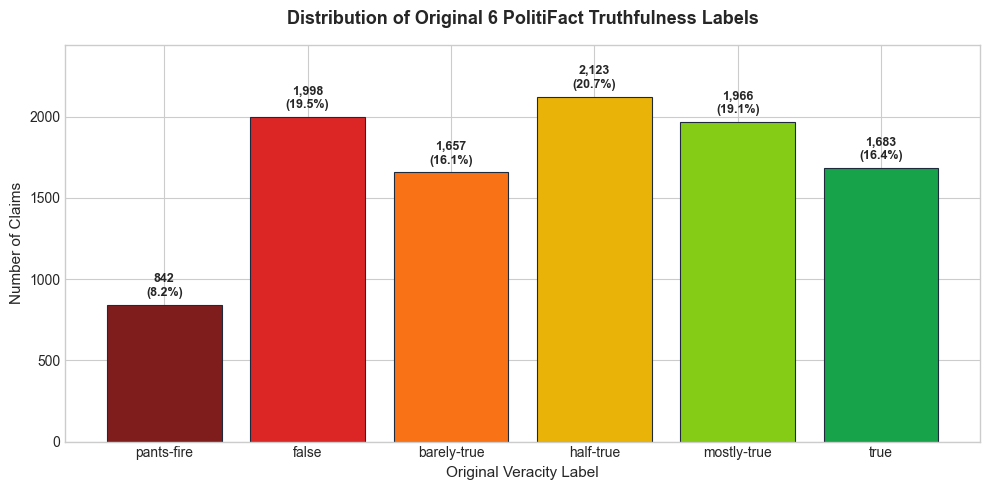

In [5]:
plt.figure(figsize=(10, 5))
order = ['pants-fire', 'false', 'barely-true', 'half-true', 'mostly-true', 'true']
label_counts = train_df['label'].value_counts().reindex(order)

colors_6 = ['#7f1d1d', '#dc2626', '#f97316', '#eab308', '#84cc16', '#16a34a']
bars = plt.bar(label_counts.index, label_counts.values, color=colors_6, edgecolor='#1e293b', linewidth=0.8)

plt.title('Distribution of Original 6 PolitiFact Truthfulness Labels', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Original Veracity Label', fontsize=11)
plt.ylabel('Number of Claims', fontsize=11)
plt.ylim(0, max(label_counts.values) * 1.15)

for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(train_df)) * 100
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 35, f"{yval:,}\n({pct:.1f}%)", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

### 4.2 Target Taxonomy Mapping (6 Classes → 3 Balanced Classes)
For production fact-checking, fine-grained political distinctions are collapsed into 3 clear operational categories:
- **`TRUE`**: `true`, `mostly-true` (Substantively verified)
- **`MISLEADING`**: `half-true`, `barely-true` (Context distorted, partial truths)
- **`FALSE`**: `false`, `pants-fire` (Outright fabrication or completely unsubstantiated)

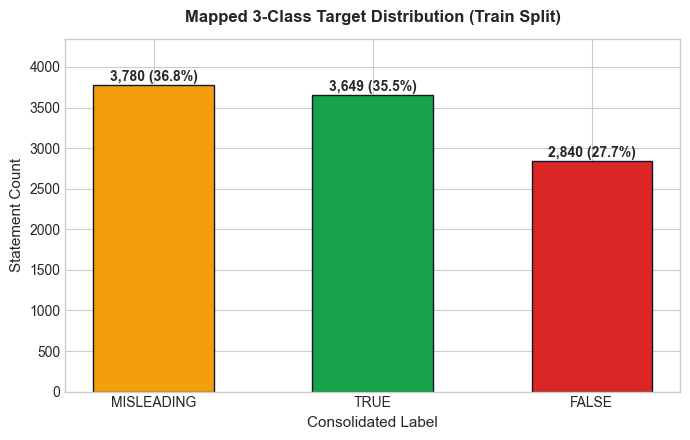

Class distribution is well-balanced across all 3 tiers:
  MISLEADING  : 3,780 (36.8%)
  TRUE        : 3,649 (35.5%)
  FALSE       : 2,840 (27.7%)


In [6]:
LABEL_MAP = {
    "true":        "TRUE",
    "mostly-true": "TRUE",
    "half-true":   "MISLEADING",
    "barely-true": "MISLEADING",
    "false":       "FALSE",
    "pants-fire":  "FALSE",
}

train_df['target_label'] = train_df['label'].map(LABEL_MAP)
valid_df['target_label'] = valid_df['label'].map(LABEL_MAP)
test_df['target_label']  = test_df['label'].map(LABEL_MAP)

plt.figure(figsize=(7, 4.5))
target_dist = train_df['target_label'].value_counts()
palette_3 = {'TRUE': '#16a34a', 'MISLEADING': '#f59e0b', 'FALSE': '#dc2626'}

bars3 = plt.bar(target_dist.index, target_dist.values, color=[palette_3[k] for k in target_dist.index], edgecolor='#0f172a', width=0.55)
plt.title('Mapped 3-Class Target Distribution (Train Split)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Consolidated Label', fontsize=11)
plt.ylabel('Statement Count', fontsize=11)
plt.ylim(0, max(target_dist.values) * 1.15)

for bar in bars3:
    yval = bar.get_height()
    pct = (yval / len(train_df)) * 100
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 50, f"{yval:,} ({pct:.1f}%)", ha='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

print("Class distribution is well-balanced across all 3 tiers:")
for lbl, cnt in target_dist.items():
    print(f"  {lbl:<12}: {cnt:,} ({cnt/len(train_df)*100:.1f}%)")

### 4.3 Statement Length & Word Count EDA
Do misleading or false statements exhibit significantly different length or structural characteristics?

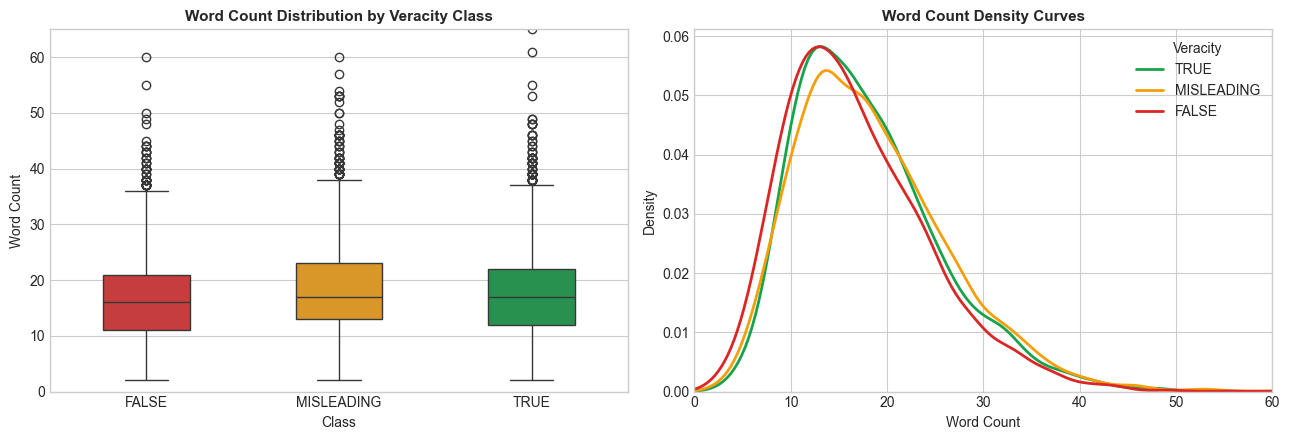

char_len              word_cnt            
                 mean median   std     mean median  std
target_label                                           
FALSE           101.0   93.0  43.9     16.9   16.0  7.5
MISLEADING      110.1  103.0  46.4     18.5   17.0  7.9
TRUE            106.6   99.0  44.2     18.1   17.0  7.6

In [7]:
train_df['char_len'] = train_df['statement'].fillna('').apply(len)
train_df['word_cnt'] = train_df['statement'].fillna('').apply(lambda s: len(s.split()))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(data=train_df, x='target_label', y='word_cnt', palette=palette_3, ax=ax1, width=0.45)
ax1.set_title('Word Count Distribution by Veracity Class', fontsize=11, fontweight='bold')
ax1.set_ylim(0, 65)
ax1.set_xlabel('Class')
ax1.set_ylabel('Word Count')

for lbl, color in palette_3.items():
    subset = train_df[train_df['target_label'] == lbl]['word_cnt']
    sns.kdeplot(subset, label=lbl, color=color, ax=ax2, linewidth=2)

ax2.set_title('Word Count Density Curves', fontsize=11, fontweight='bold')
ax2.set_xlim(0, 60)
ax2.set_xlabel('Word Count')
ax2.legend(title='Veracity')

plt.tight_layout()
plt.show()

display(train_df.groupby('target_label')[['char_len', 'word_cnt']].agg(['mean', 'median', 'std']).round(1))

### 4.4 Top Speakers & Veracity Ratio
Analyze the distribution of truthfulness among the most frequently cited public figures.

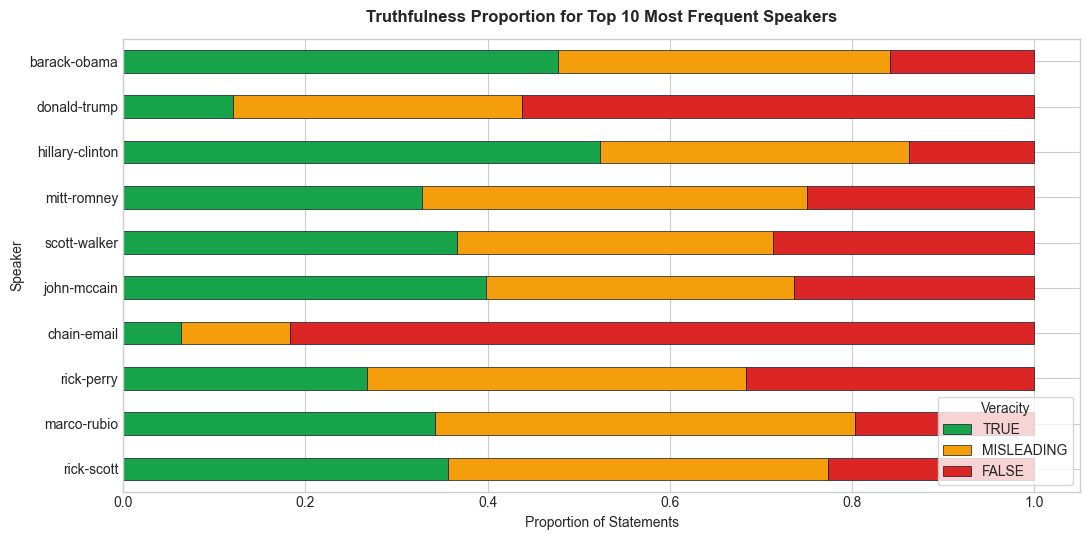

In [8]:
top_speakers = train_df['speaker'].value_counts().head(10).index
speaker_subset = train_df[train_df['speaker'].isin(top_speakers)]

ct = pd.crosstab(speaker_subset['speaker'], speaker_subset['target_label'], normalize='index')
ct = ct[['TRUE', 'MISLEADING', 'FALSE']].loc[top_speakers]

fig, ax = plt.subplots(figsize=(11, 5.5))
ct.plot(kind='barh', stacked=True, color=['#16a34a', '#f59e0b', '#dc2626'], ax=ax, edgecolor='#0f172a', linewidth=0.5)

plt.title('Truthfulness Proportion for Top 10 Most Frequent Speakers', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Proportion of Statements')
plt.ylabel('Speaker')
plt.legend(title='Veracity', loc='lower right', frameon=True)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### 4.5 Top Subject Categories in Contested Claims
Unpack the multi-tag subjects to discover the top domains of public discourse.

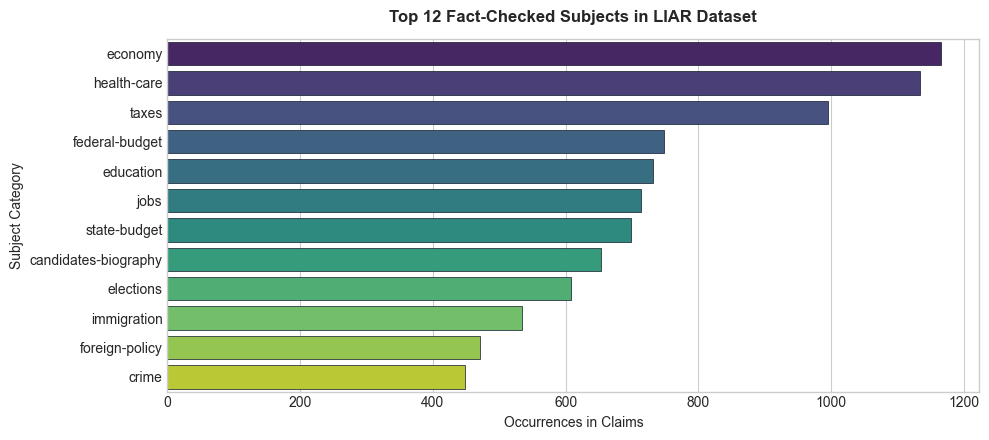

In [9]:
subject_list = []
for s in train_df['subjects'].dropna():
    subject_list.extend([x.strip().lower() for x in s.split(',') if x.strip()])

top_subj = pd.Series(subject_list).value_counts().head(12)

plt.figure(figsize=(10, 4.5))
sns.barplot(x=top_subj.values, y=top_subj.index, palette='viridis', edgecolor='#0f172a', linewidth=0.5)
plt.title('Top 12 Fact-Checked Subjects in LIAR Dataset', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Occurrences in Claims')
plt.ylabel('Subject Category')
plt.tight_layout()
plt.show()

## 5. Text Preprocessing Pipeline
Construct robust text normalization functions:
1. **Lowercasing:** Canonical text representation.
2. **URL & HTML Removal:** Strips web links and formatting tags.
3. **Special Character Sanitization:** Retains semantic alphanumeric words.
4. **Composite Context Fusion:** Concatenates claim text with speaker, topic, and context metadata.

In [10]:
def clean_text(text: str) -> str:
    """Sanitizes text by removing web artifacts, special characters, and excessive whitespace."""
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)  # remove URLs
    text = re.sub(r'<.*?>', ' ', text)                  # remove HTML tags
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)            # remove non-alphabetic chars
    text = re.sub(r'\s+', ' ', text).strip()            # collapse whitespace
    return text

def build_composite_features(df: pd.DataFrame) -> pd.Series:
    """Fuses the statement with topic, speaker, and context signals for optimal NLP feature representation."""
    combined = (
        df['statement'].fillna('').apply(clean_text) + ' ' +
        df['subjects'].fillna('').apply(clean_text) + ' ' +
        df['speaker'].fillna('').apply(clean_text) + ' ' +
        df['job'].fillna('').apply(clean_text) + ' ' +
        df['context'].fillna('').apply(clean_text)
    )
    return combined.str.strip()

# Apply to train, valid, and test sets
train_df['clean_statement'] = train_df['statement'].apply(clean_text)
train_df['composite_text']  = build_composite_features(train_df)

valid_df['clean_statement'] = valid_df['statement'].apply(clean_text)
valid_df['composite_text']  = build_composite_features(valid_df)

test_df['clean_statement']  = test_df['statement'].apply(clean_text)
test_df['composite_text']   = build_composite_features(test_df)

print("Sample cleaned comparison:")
print("-" * 70)
idx = 2
print("Raw Statement:      ", train_df['statement'].iloc[idx][:120], "...")
print("Cleaned Statement:  ", train_df['clean_statement'].iloc[idx][:120], "...")
print("Composite Feature:  ", train_df['composite_text'].iloc[idx][:120], "...")

Sample cleaned comparison:
----------------------------------------------------------------------
Raw Statement:       Hillary Clinton agrees with John McCain "by voting to give George Bush the benefit of the doubt on Iran." ...
Cleaned Statement:   hillary clinton agrees with john mccain by voting to give george bush the benefit of the doubt on iran ...
Composite Feature:   hillary clinton agrees with john mccain by voting to give george bush the benefit of the doubt on iran foreign policy ba ...


## 6. Feature Extraction & N-Gram EDA (TF-IDF)
Fit a Term Frequency-Inverse Document Frequency (TF-IDF) vectorizer to extract discriminative vocabulary and top n-grams across veracity labels.

In [11]:
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),        # Unigrams + Bigrams
    max_features=5000,         # Top 5,000 vocabulary items
    stop_words='english',      # Remove standard English stopwords
    sublinear_tf=True,         # Logarithmic term frequency scaling
    min_df=2
)

X_train_tfidf = tfidf_vectorizer.fit_transform(train_df['composite_text'])
feature_names = np.array(tfidf_vectorizer.get_feature_names_out())

print(f"Extracted TF-IDF Sparse Matrix: {X_train_tfidf.shape[0]:,} documents x {X_train_tfidf.shape[1]:,} features")

Extracted TF-IDF Sparse Matrix: 10,269 documents x 5,000 features


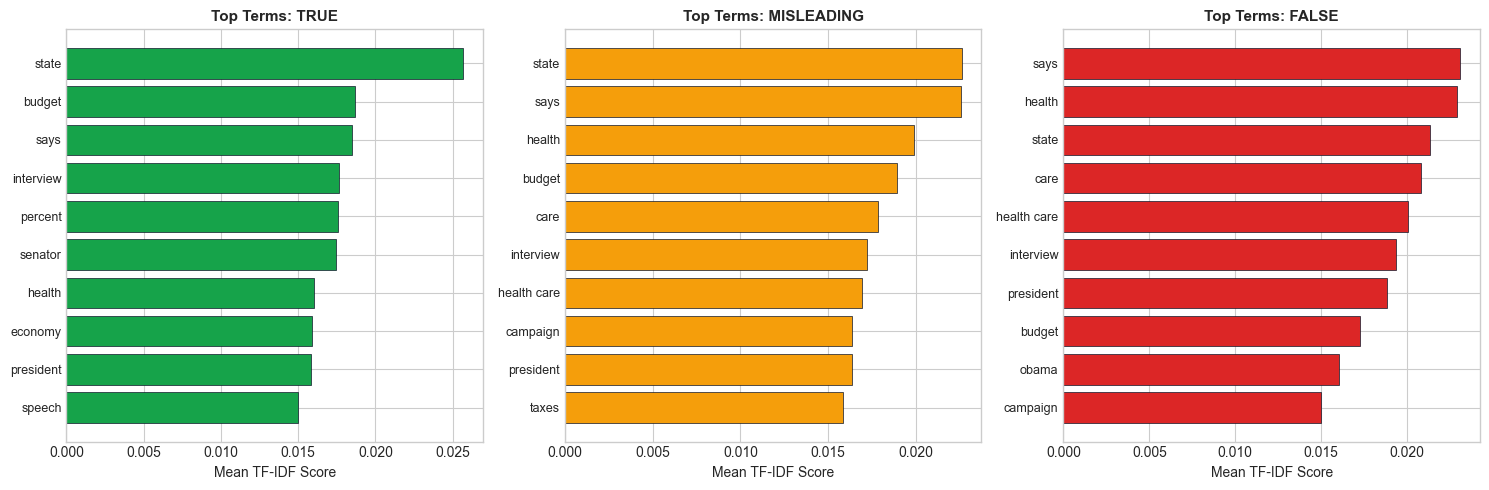

In [12]:
# Display top 10 most characteristic TF-IDF n-grams per veracity label
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, (label, color) in enumerate(palette_3.items()):
    mask = (train_df['target_label'] == label).values
    mean_scores = np.asarray(X_train_tfidf[mask].mean(axis=0)).flatten()
    top_indices = mean_scores.argsort()[-10:][::-1]
    
    top_words = feature_names[top_indices]
    top_values = mean_scores[top_indices]
    
    axes[i].barh(range(len(top_words)), top_values, color=color, edgecolor='#0f172a', linewidth=0.5)
    axes[i].set_yticks(range(len(top_words)))
    axes[i].set_yticklabels(top_words, fontsize=9)
    axes[i].invert_yaxis()
    axes[i].set_title(f'Top Terms: {label}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Mean TF-IDF Score')

plt.tight_layout()
plt.show()

## 7. Pipeline Readiness & Summary

| Phase | Completed Action | Key Output |
|---|---|---|
| **1. Data Ingestion** | Loaded 12,836 statements across Train, Valid, and Test splits | Complete dataframe with 14 benchmark attributes |
| **2. EDA** | Analyzed class distributions, speaker truth ratios, and topic frequencies | Validated balanced 3-class target mapping (`TRUE`, `MISLEADING`, `FALSE`) |
| **3. Text Preprocessing** | URL/HTML removal, punctuation stripping, whitespace normalization | Clean normalized text strings |
| **4. Feature Engineering** | Fused statement with speaker, topic, and context metadata | `composite_text` with rich context |
| **5. N-Gram Extraction** | TF-IDF unigrams & bigrams with sublinear scaling | Top discriminating vocabulary identified |

### 🚀 Next Step: Model Training & Deployment
To train the production Multinomial Logistic Regression model and serve it via FastAPI:
```bash
cd ../ml_service
./venv/bin/python3 train.py
./venv/bin/python3 app.py
```